**LIBRARIES AND HELPING FUNCTIONS**


In [33]:
#Importing necessary libraries
import numpy as np
import math
import time 
import matplotlib.pyplot as plt 

############## Functions for Quest1 ##############

#Function to calculate the determinant of 3 points 
def det(a,b,c):

  x0, y0 = a
  x1, y1 = b
  x2, y2 = c
  
  #det() < 0 --> CW, det() > 0 --> CCW
  return x0*(y1-y2) + x1*(y2-y0) + x2*(y0-y1)

#Function to calculate if point b is interior point of a and c
def isInterior(a,b,c):

  x0, y0 = a
  x1, y1 = b
  x2, y2 = c

  dab = (x1 - x0)**2 + (y1 - y0)**2
  dbc = (x2 - x1)**2 + (y2 - y1)**2
  dac = (x2 - x0)**2 + (y2 - y0)**2

  #True if b is interior point of a and c (using epsilon for floating point precision)
  return abs(dab + dbc - dac) < 1e-9


#Function of merging upper and lower bridges
def bridge(A, B):

  if len(A) == 0:
    return B
  if len(B) == 0:
    return A
  
  #Getting the rightmost point of A (not necessarily sorted A)
  i = 0
  for k in range(0,len(A)):
    if A[k][0] > A[i][0]:
      i = k

  #Getting the leftmost point of B (not necessarily sorted B)
  j = 0
  for k in range(0,len(B)):
    if B[k][0] < B[j][0]:
      j = k

  #Finding upper bridge
  while True:
    changed = False
    
    #Moving clockwise in A
    while det(B[j], A[i], A[(i+1)%len(A)]) < 0:
      i = (i + 1) % len(A)
      changed = True

    #Moving counterclockwise in B
    while det(A[i], B[j], B[(j-1)%len(B)]) > 0:
      j = (j - 1) % len(B)
      changed = True

    if not changed:
      break
  
  upperBridge = (i,j)

  #Getting the rightmost point of A (not necessarily sorted A)
  i = 0
  for k in range(0,len(A)):
    if A[k][0] > A[i][0]:
      i = k

  #Getting the leftmost point of B (not necessarily sorted B)
  j = 0
  for k in range(0,len(B)):
    if B[k][0] < B[j][0]:
      j = k

  #Finding lower bridge
  while True:
    changed = False
    
    #Moving clockwise in B
    while det(A[i], B[j], B[(j+1)%len(B)]) < 0:
      j = (j + 1) % len(B)
      changed = True

    #Moving counterclockwise in A
    while det(B[j], A[i], A[(i-1)%len(A)]) > 0:
      i = (i - 1) % len(A)
      changed = True

    if not changed:
      break
  
  lowerBridge = (i,j)

  #Merging the two hulls
  result = []

  i = upperBridge[0]
  while True:
    result.append(A[i])
    if i == lowerBridge[0]:
      break
    i = (i + 1) % len(A)

  j = lowerBridge[1]
  while True:
    result.append(B[j])
    if j == upperBridge[1]:
      break
    j = (j + 1) % len(B)
  
  return result

#Function to calculate distance from point a to a line defined by points b and c
def pointLineDistance(a,b,c):

  x0, y0 = a
  x1, y1 = b
  x2, y2 = c

  return  abs((y2 - y1)*x0 - (x2 - x1)*y0 + x2*y1 - y2*x1) / math.sqrt((y2 - y1)**2 + (x2 - x1)**2)


############## Functions for Quest3 ##############

#Function to lift 2D points to 3D paraboloid for delaunay triangulation
def pointsLifitng(points):
  
  liftedPoints = []

  for p in points:
    x, y = p
    z = x**2 + y**2
    liftedPoints.append((x,y,z))
  
  return np.array(liftedPoints)


############## Functions for Quest4 ##############


#Function to update the bounds of subtree
def updateBounds(bounds, point, axis):

  xMin, xMax, yMin, yMax = bounds

  #Splitting along x axis
  if axis == 0:

    left = (xMin, point[0], yMin, yMax)
    right = (point[0], xMax, yMin, yMax)

  #Splitting along y axis
  else:

    left = (xMin, xMax, yMin, point[1])
    right = (xMin, xMax, point[1], yMax)

  return left, right

**ΑΛΓΟΡΙΘΜΟΣ GRAHAM'S SCAN (ΑΥΞΗΤΙΚΟΣ)**

Πολυπλοκότητα --> $O(nlogn)$

In [34]:
#Implementation of Graham's Scan Algorithm
def GrahamScan(points):

  #Sorting the points based on the x coordinate
  sortedPoints = sorted(points, key=lambda point: point[0])

  #Adding the first two elements to the list
  L_upper = [sortedPoints[0], sortedPoints[1]]

  #Building the L_upper 
  for i in range(2, len(sortedPoints)):
    L_upper.append(sortedPoints[i])

    #Getting the last three elements and calculating the determinant
    while len(L_upper) > 2 and det(L_upper[- 3], L_upper[-2], L_upper[-1]) > 0:
      del L_upper[-2]
  
  #Adding the last two elements to the list
  L_lower = [sortedPoints[len(sortedPoints)-1], sortedPoints[len(sortedPoints)-2]]

  #Building the L_lower
  for i in range(len(sortedPoints)-3, -1, -1):
    L_lower.append(sortedPoints[i])

    #Getting the last three elements and calculating the determinant
    while len(L_lower) > 2 and det(L_lower[- 3], L_lower[-2], L_lower[-1]) > 0:
      del L_lower[-2]
  
  #Removing first and last element of L_lower to avoid duplication
  del L_lower[0]
  del L_lower[-1]

  convexHull = L_upper + L_lower
  return convexHull

**ΑΛΓΟΡΙΘΜΟΣ GIFTWRAPPING (ΠΕΡΙΤΥΛΙΓΜΑΤΟΣ)**

Πολυπλοκότητα --> $Ο(n^2)$

In [35]:
#Implementation of GiftWrapping Algorithm
def GiftWrapping(points):

  #Sorting the points based on the x coordinate and y coordinate if x are equal
  sortedPoints = sorted(points, key=lambda point: (point[0], point[1]))

  S = set(sortedPoints)

  #Initializing r to the point with the lowest x coordinate
  rMin = sortedPoints[0]
  r = rMin
  convexHull = [rMin]

  #Following the Gift Wrapping Algorithm steps
  while True:

    u = None

    for t in S:

      if t == r:
        continue
      if u is None:
        u = t
        continue
      if det(r, u, t) < 0 or isInterior(r, u , t):
        u = t
    
    if u == rMin:
      break

    r = u
    convexHull.append(r)

  return list(convexHull)

**ΑΛΓΟΡΙΘΜΟΣ DIVIDE AND CONQUER (ΔΙΑΙΡΕΙ ΚΑΙ ΒΑΣΙΛΕΥΕ)**

Πολυπλοκότητα --> $O(nlogn)$

In [36]:
#Implmentation of Divide and Conquer Algorithm
def DivideAndConquer(points):

  if len(points) <= 1:
    return points
  
  #Sorting the points based on the x coordinate
  sortedPoints = sorted(points, key=lambda point: point[0])

  #Slicing the list into two halves
  A  = sortedPoints[:math.floor(len(sortedPoints)/2)]
  B = sortedPoints[math.floor(len(sortedPoints)/2):]

  #Recursively calling the function on both halves
  Apoints = DivideAndConquer(A)
  Bpoints = DivideAndConquer(B)

  #Merging the two convex hulls with upper and lower bridge
  convexHull = bridge(Apoints, Bpoints)
  return convexHull

**ΑΛΓΟΡΙΘΜΟΣ QUICKHULL**

Πολυπλοκότητα --> $O(nlogn)$

In [37]:
#Implmentation of QuickHull Algorithm
def QuickHullRecursive(S,A,B):

  if len(S) == 0:
    return []
  
  #Finding the point in S that is farthest from line AB
  farthestPoint = S[0]

  for point in S:
    if pointLineDistance(point, A, B) > pointLineDistance(farthestPoint, A, B):
      farthestPoint = point

  #Dividing the set S into two subsets S1 and S2
  M = []
  N = []

  for point in S:
    if det(A, farthestPoint, point) < 0:
      M.append(point)
    if det(farthestPoint, B, point) < 0:
      N.append(point)

  #Recursively calling QuickHull on both subsets
  hull1 = QuickHullRecursive(M, A, farthestPoint)
  hull2 = QuickHullRecursive(N, farthestPoint, B)

  #Combining the results
  return hull1 + [farthestPoint] + hull2

def QuickHull(points):
  
  #Sorting the points based on the x coordinate
  sortedPoints = sorted(points, key=lambda point: point[0])

  #Finding extreme points A and B
  A = sortedPoints[0]
  B = sortedPoints[-1]

  #Dividing the set of points into two subsets S1 and S2
  S1 = []
  S2 = []

  for point in sortedPoints:
    # Points to the left of AB go to S1, to the right go to S2
    if det(A, B, point) < 0:
      S1.append(point)
    elif det(B, A, point) < 0:
      S2.append(point)

  #Recursively calling QuickHull on both subsets
  hull1 = QuickHullRecursive(S1, A, B)
  hull2 = QuickHullRecursive(S2, B, A)

  #Combining the results
  convexHull = [A] + hull1 + [B] + hull2
  return convexHull


**ΕΥΡΕΣΗ ΚΥΡΤΟΥ ΠΕΡΙΒΛΗΜΑΤΟΣ**

Number of points: 200
Graham's Scanner:	 Time taken: 0.001116 seconds
Gift Wrapping:		 Time taken: 0.008741 seconds
Divide and Conquer:	 Time taken: 0.002035 seconds
QuickHull:		 Time taken: 0.001679 seconds


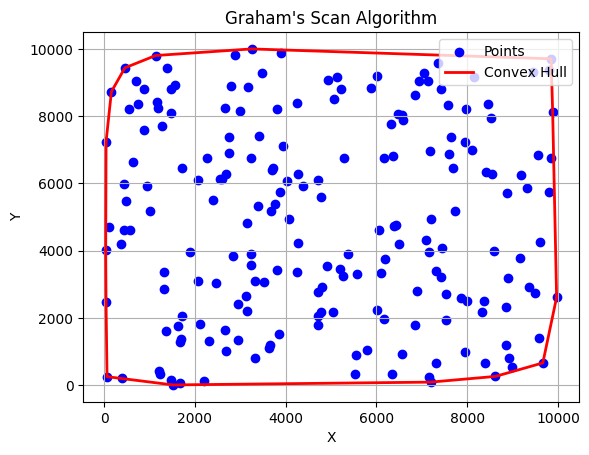

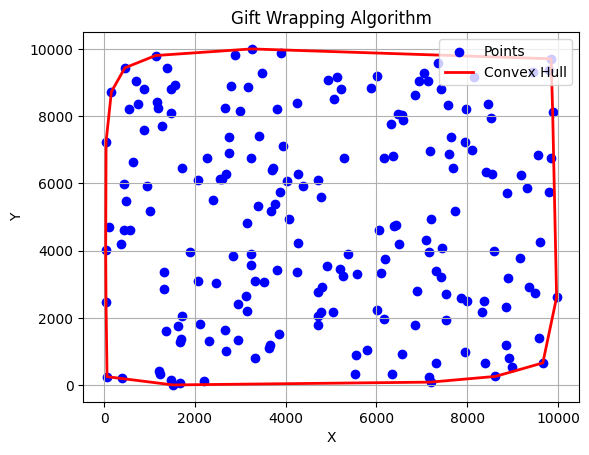

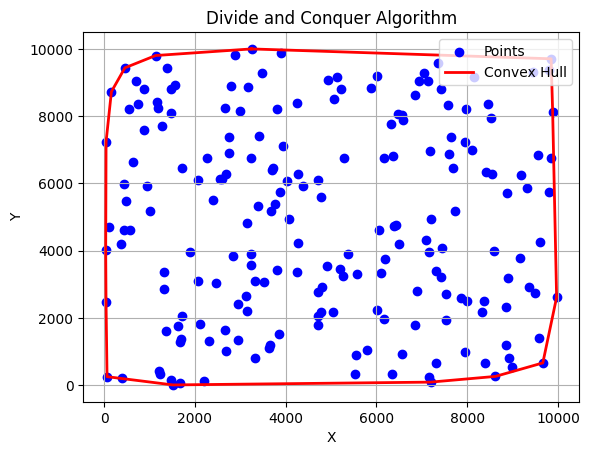

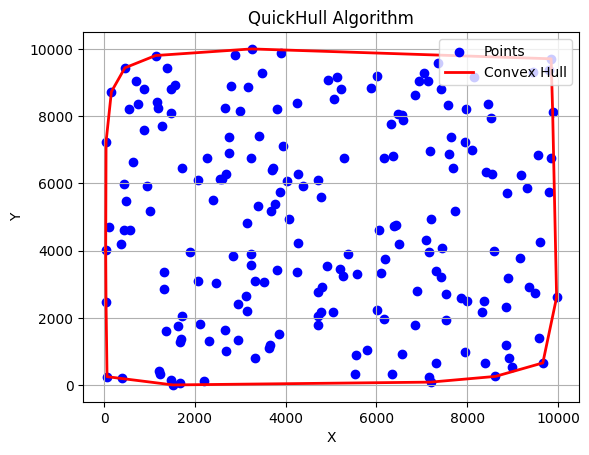

In [38]:
#Creating 200 random points (x and y coordinates between 0 and 10000)
np.random.seed(1926)
randomPoints1 = np.random.uniform(low=0,high=10000,size=(200, 2))
x = randomPoints1[:,0]
y = randomPoints1[:,1] 
points = list(zip(x,y))

print("Number of points:", len(points))

#Graham's Scan Algorithm
GrahamScanStart = time.perf_counter()
GrahamScanResult = GrahamScan(points)
GrahamScanEnd = time.perf_counter()
GrahamScanElapsed = GrahamScanEnd - GrahamScanStart

#Gift Wrapping Algorithm
GiftWrappingStart = time.perf_counter()
GiftWrappingResult = GiftWrapping(points)
GiftWrappingEnd = time.perf_counter()
GiftWrappingElapsed = GiftWrappingEnd - GiftWrappingStart

#Divide and Conquer Algorithm
DivideConquerStart = time.perf_counter()
DivideConquerResult = DivideAndConquer(points)
DivideConquerEnd = time.perf_counter()
DivideElapsed = DivideConquerEnd - DivideConquerStart

#QuickHull Algorithm
QuickHullStart = time.perf_counter()
QuickHullResult = QuickHull(points)
QuickHullEnd = time.perf_counter()
QuickHullElapsed = QuickHullEnd - QuickHullStart

#Getting Coordinates of every algorithm separately
GrahamScanX, GrahamScanY = zip(*GrahamScanResult)
GiftWrappingX, GiftWrappingY = zip(*GiftWrappingResult)
DivideX, DivideY = zip(*DivideConquerResult)
QuickHullX, QuickHullY = zip(*QuickHullResult)

#Printing the results
print(f'Graham\'s Scanner:\t Time taken: {GrahamScanElapsed:.6f} seconds')
print(f'Gift Wrapping:\t\t Time taken: {GiftWrappingElapsed:.6f} seconds')
print(f'Divide and Conquer:\t Time taken: {DivideElapsed:.6f} seconds')
print(f'QuickHull:\t\t Time taken: {QuickHullElapsed:.6f} seconds')


#Plotting the results of Graham's Scan
plt.scatter(x, y, color='blue', marker='o', label='Points')
plt.plot(GrahamScanX + (GrahamScanX[0],), GrahamScanY + (GrahamScanY[0],), color='red', linewidth=2, label='Convex Hull')
plt.title("Graham's Scan Algorithm")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

#Plotting the results of Gift Wrapping
plt.scatter(x, y, color='blue', marker='o', label='Points')
plt.plot(list(GiftWrappingX) + [GiftWrappingX[0]], list(GiftWrappingY) + [GiftWrappingY[0]], color='red', linewidth=2, label='Convex Hull')
plt.title("Gift Wrapping Algorithm")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

#Plotting the results of Divide and Conquer
plt.scatter(x, y, color='blue', marker='o', label='Points')
plt.plot(DivideX+ (DivideX[0],), DivideY + (DivideY[0],), color='red', linewidth=2, label='Convex Hull')
plt.title("Divide and Conquer Algorithm")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


#Plotting the results of QuickHull
plt.scatter(x, y, color='blue', marker='o', label='Points')
plt.plot(QuickHullX + (QuickHullX[0],), QuickHullY + (QuickHullY[0],), color='red', linewidth=2, label='Convex Hull')
plt.title("QuickHull Algorithm")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend(loc='upper right')
plt.grid(True)
plt.show()  

Παρατηρούμε ότι και τα 4 παραπάνω διαγράμματα είναι ίδια ανεξάρτητα από τον αλγόριθμο που χρησιμοποιείται. Βέβαια ο χρόνος εκτέλεσης του Divide and Conquer (Διαίρει και Βασίλευε) είναι μεγαλύτερος. Αναμενόμενο αφού έχει πολυπλοκότητα O($n^2$) ενώ οι υπόλοιποι έχουν O(nlogn). 

Στον παρακάτω πίνακα παρουσιάζονται τα χρονικά αποτελέσματα σε δευτερόλεπτα των αλγορίθμων (με ακρίβεια 6 δεκαδικών ψηφίων) για 100, 200, 500 και 1000 τυχαία σημεία. Χρησιμοποιήθηκε βέβαια παντού το seed 1926 ώστε να είμαστε σίγουροι ότι μιλάμε για τα ίδια στοιχεία. 



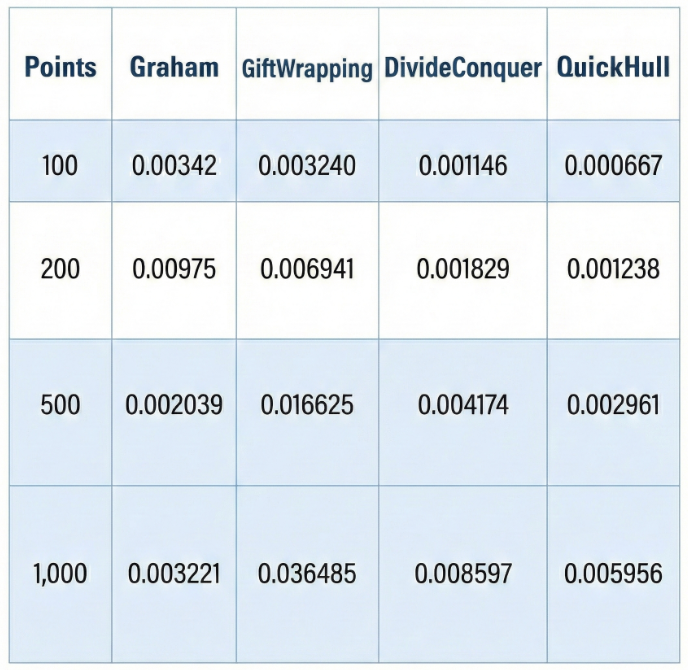

In [39]:
from IPython.display import Image
Image(filename='images/results_table.png')

**ΑΛΓΟΡΙΘΜΟΣ QUICKHULL ΓΙΑ ΚΥΡΤΟ ΠΕΡΙΒΛΗΜΑ 3D**

Worst-case Πολυπλοκότητα --> $O(n^2)$

Μέσω της βιβλιοθήκης **scipy.spatial** της ConvexHull χρησιμοποιείται ο αλγόριθμος QuickHull σε 3d. Ο αλγόριθμος αυτός αρχικά βρίσκει 6 ακραία μη συνεπίπεδα σημεία (*xmin,xmax,ymin,ymax,zmin,zmax*). Στη συνέχεια αγνοούνται όσα σημεία βρίσκονται εντός του κυρτού περιβλήματος των 6 ακραίων σημείων αφού δεν μπορούν να προσθέσουν παραπάνω έδρες , ακμές , κορυφές. Διαλέγονται τα σημεία που απέχουν περισσότερο από τις έδρες του κυρτού περιβλήματος και βρίσκονται οι ορατές επιφάνειες των σημείων αυτών . Αφαιρούνται οι ορατές έδρες και ακμές και προστίθονται νέες έδρες από τα σημεία αυτά προς τις ακμές του κυρτού περιβλήματος. Η διαδικασία επαναλμβάνεται μέχρι όλα τα σημεία να είναι εντός του κυρτού περιβλήματος. 

Πηγή: https://en.wikipedia.org/wiki/Quickhull

In [40]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

#Function to plot the 3D convex hull
def plotHull(points, hullFaces):
    
    #Creating a 3D plot
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    #Taking the coordinates of the points and plotting them
    x, y, z = zip(*points)
    ax.scatter(x, y, z, color='blue', marker='o', label='Points')

    for face in hullFaces:
        #Taking the vertices of each face (triangle) and plotting them
        v0, v1, v2 = face 
        vertices = [v0, v1, v2]
        ax.add_collection3d(Poly3DCollection([vertices], linewidths=0.8, edgecolors='red', alpha=.25))


    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title('3D Convex Hull')
    plt.legend()
    plt.show()

Number of Points: 180


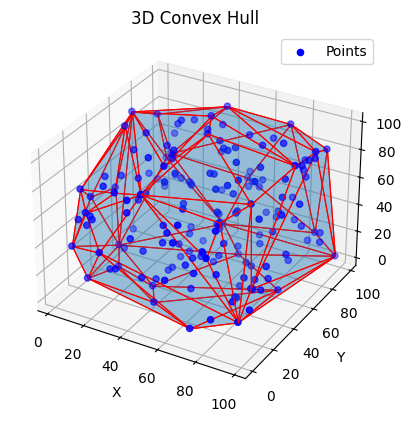

In [41]:
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial import ConvexHull

#Creating random x,y coordinates
np.random.seed(4)
randomPoints2 = np.random.uniform(low=0,high=100,size=(180,3))

x = randomPoints2[:,0]
y = randomPoints2[:,1]
z = randomPoints2[:,2]
points = np.array(randomPoints2)
print("Number of Points:",len(points))

#Calculating the convex hull using ConvexHull of the library
hull = ConvexHull(points)
result = [points[simplex] for simplex in hull.simplices]


#Using the plotHull function to plot the convex hull
plotHull(points,result)

**ΓΡΑΜΜΙΚΟΣ ΠΡΟΓΡΑΜΜΑΤΙΣΜΟΣ**

Πολυπλοκότητα --> $O(n^2)$

In [42]:
from scipy.optimize import linprog

#Implementation of Incremental Linear Programming Algorithm
def IncrementalLinearProgramming(A,b,c):

  #Defining the bounds of the variables x,y
  xBound = (0, None)
  yBound = (0, None)

  A = np.array(A)
  b = np.array(b)

  #Taking the number of constraints and variables
  constraints , d = A.shape

  #Keepping only the first d+1 constraints
  Acurrent = A[:d+1]
  bcurrent = b[:d+1]

  #Finding optimized solution for the first d+1 constraints
  xStar = linprog(c, A_ub=Acurrent, b_ub=bcurrent, bounds=[xBound, yBound], method='simplex')
  if not xStar.success:
    return "Unbounded"
  
  #Incrementally adding the remaining constraints
  for i in range(d+1, len(A)):
    xStar = linprog(c, A_ub=A[:i], b_ub=b[:i], bounds=[xBound, yBound], method='simplex')
    if not xStar.success:
      return "Unbounded"
  
  return xStar

C:\Users\oikon\AppData\Local\Temp\ipykernel_15196\334061052.py:21: DeprecationWarning: `method='simplex'` is deprecated and will be removed in SciPy 1.11.0. Please use one of the HiGHS solvers (e.g. `method='highs'`) in new code.
  xStar = linprog(c, A_ub=Acurrent, b_ub=bcurrent, bounds=[xBound, yBound], method='simplex')
C:\Users\oikon\AppData\Local\Temp\ipykernel_15196\334061052.py:27: DeprecationWarning: `method='simplex'` is deprecated and will be removed in SciPy 1.11.0. Please use one of the HiGHS solvers (e.g. `method='highs'`) in new code.
  xStar = linprog(c, A_ub=A[:i], b_ub=b[:i], bounds=[xBound, yBound], method='simplex')


 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 17.0
       x: [ 1.814e+01  6.143e+00]
     nit: 9


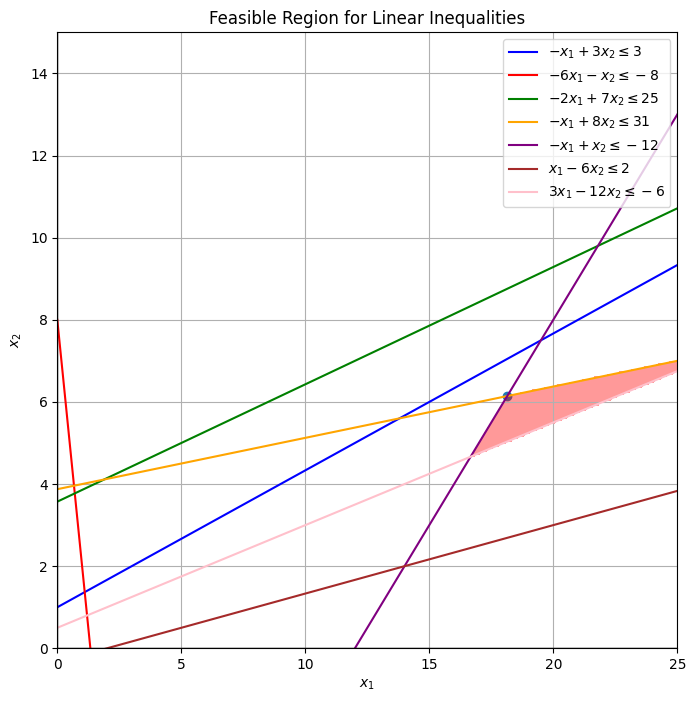

In [43]:
#Solution of the given linear programming problem
c = [5, -12]        # max{-5x_1 + 12x_2} -> min{5x_1 - 12x_2}

A = [
      [-1, 3],      # -x_1 + 3x_2 <= 3
      [-6, -1],     # -6x_1 - x_2 <= -8
      [-2, 7],      # -2x_1 + 7x_2 <= 25
      [-1, 8],      # -x_1 + 8x_2 <= 31
      [-1, 1],      # -x_1 + x_2 <= -12
      [1, -6],      # x_1 - 6x_2 <= 2
      [3, -12]      # 3x_1 - 12x_2 <= -6  
    ]

b = [3, -8, 25, 31, -12, 2, -6]

result  = IncrementalLinearProgramming(A,b,c)
print(result)

point = result.x

#Plotting the feasible region and the optimal solution

x1 = np.linspace(0, 25, 400)
x2 = np.linspace(0, 25, 400)
X1, X2 = np.meshgrid(x1, x2)

#Inequlity1 : -x1 + 3x2 <= 3 --> x2 <= (3 + x1)/3
x2_1 = (3 + x1) / 3

#Inequality2 : -6x1 - x2 <= -8 --> x2 >= (8 - 6*x1)
x2_2 = 8 - 6*x1

#Inequality3 : -2x1 + 7x2 <= 25 --> x2 <= (25 + 2*x1)/7
x2_3= (25 + 2*x1) / 7

#Inequality4 : -x1 + 8x2 <= 31 --> x2 <= (31 + x1)/8
x2_4 = (31 + x1) / 8  

#Inequality5 : -x1 + x2 <= -12 --> x2 <= x1 - 12
x2_5 = -12 + x1

#Inequality6 : x1 - 6x2 <= 2 --> x2 >= (x1 - 2)/6
x2_6 = (x1 - 2) / 6

#Inequality7 : 3x1 - 12x2 <= -6 --> x2 >= (3*x1 + 6)/12
x2_7 = (3*x1 + 6) / 12

#Evaluating inequalities for feasible region
constraint1 = X2 <= (3 + X1) / 3
constraint2 = X2 >= 8 - 6*X1 
constraint3 = X2 <= (25 + 2*X1) / 7
constraint4 = X2 <= (31 + X1) / 8
constraint5 = X2 <= -12 + X1
constraint6 = X2 >= (X1 - 2) / 6
constraint7 = X2 >= (3*X1 + 6) / 12



#Combining all constraints
feasibleRegion = (constraint1 & constraint2 & constraint3 & constraint4 & constraint5 & constraint6 & constraint7)

plt.figure(figsize=(8,8))

#Boundary lines
plt.plot(x1, x2_1, label=r'$-x_1 + 3x_2 \leq 3$',color='blue')
plt.plot(x1, x2_2, label=r'$-6x_1 - x_2 \leq -8$',color='red')
plt.plot(x1, x2_3, label=r'$-2x_1 + 7x_2 \leq 25$',color='green')
plt.plot(x1, x2_4, label=r'$-x_1 + 8x_2 \leq 31$',color='orange')
plt.plot(x1, x2_5, label=r'$-x_1 + x_2 \leq -12$',color='purple')
plt.plot(x1, x2_6, label=r'$x_1 - 6x_2 \leq 2$',color='brown')
plt.plot(x1, x2_7, label=r'$3x_1 - 12x_2 \leq -6$',color='pink')

plt.scatter(point[0],point[1])

#Shading the feasible region
plt.contourf(X1, X2, feasibleRegion, levels=[0.5, 1], colors=['red'], alpha=0.4)

#Plotting, Axes , Labels and Legends
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.xlim(0, 25)
plt.ylim(0, 15)
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.title('Feasible Region for Linear Inequalities')
plt.legend(loc='upper right')

plt.grid(True)
plt.show()

Όπως φαίνεται έχει υλοποιηθεί ο αυξητικός αλγόριθμος για την επίλυση του προβλήματος. Όλες οι ανισότητες και η αντικειμενική συνάρτηση κανονικοποιήθηκαν και χρησιμοποιήθηκε η μέθοδος Simplex της βιβλιοθήκης **scipy.optimize** της linprog. Ξεκινώντας από μια βασική εφικτή λύση κάθε φορά πηγαίνει σε μια άλλη μέχρι να βρεθεί η βέλτιστη (εκείνη που μεγιστοποιεί ή ελαχιστοποιεί αντίστοιχα την αντικειμενική συνάρτηση). Σε κάθε βήμα παρατηρείται η συνεισφορά των μεταβλητών εκτός βάσης στην αντικειμενική συνάρτηση. Ο αλγόριθμος τερματίζει όταν καμία μεταβλητή δεν έχει θετική συνεισφορά στην αντικειμενική συνάρτηση. Στο παραπάνω διάγραμμα φαίνεται η εφικτή περιοχή που σχηματίζουν οι ανισότητες με λύση να είναι η **(x,y)=(1.814,1.614)**.  

**ΤΡΙΓΩΝΟΠΟΙΗΣΗ DELAUNAY**

Πολυπλοκότητα --> $O(nlogn)$

In [44]:
from scipy.spatial import ConvexHull
from mpl_toolkits.mplot3d import Axes3D

def DelaunayLifting(points):
  
  #Lifting the points to 3D paraboloid
  liftedPoints = pointsLifitng(points)

  #Calculating the convex hull
  hull = ConvexHull(liftedPoints)

  #Taking only the faces of the convex hull we want for Delaunay triangulation
  delaunayFaces = []

  for simplex in hull.simplices:
    v0, v1, v2 = liftedPoints[simplex]

    #Checking if the face is a lower face (normal vector's z component < 0)
    normalVector = np.cross(v1 - v0, v2 - v0)
    if normalVector[2] < 0:
      delaunayFaces.append(simplex)
  
  return np.array(delaunayFaces) , liftedPoints , hull

Delaunay Lifting Algorithm:	 Time taken: 0.004917 seconds


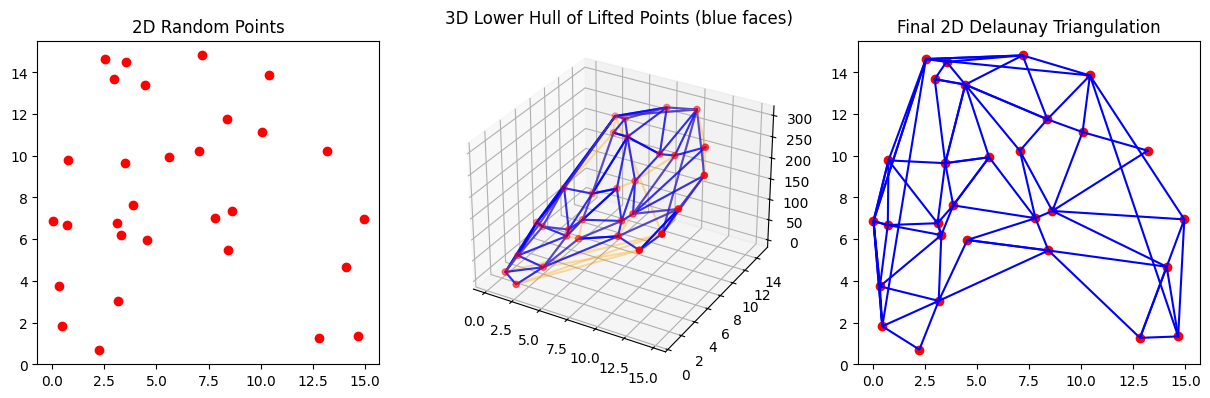

In [49]:
#Creating 30 random points (x and y coordinates between 0 and 15)
np.random.seed(2026)
randomPoints4 = np.random.uniform(low=0,high=15,size=(30,2))

#Running Delaunay Lifting Algorithm
delaunaystart = time.perf_counter()
triangles, liftedPoints, hull = DelaunayLifting(randomPoints4)
delaunayend = time.perf_counter()
delaunayelapsed = delaunayend - delaunaystart
print(f'Delaunay Lifting Algorithm:\t Time taken: {delaunayelapsed:.6f} seconds')
figure = plt.figure(figsize=(15,15))

#2D plot of original points
ax1 = figure.add_subplot(131)
ax1.scatter(randomPoints4[:,0], randomPoints4[:,1], color='red')
ax1.set_title('2D Random Points')
ax1.set_aspect('equal')

#3D plot of blue lower hull faces
ax2 = figure.add_subplot(132, projection='3d')
ax2.scatter(liftedPoints[:,0], liftedPoints[:,1], liftedPoints[:,2], color='red')
ax2.set_title('3D Lower Hull of Lifted Points (blue faces)')

#Plotting the convex hull faces
for simplex in hull.simplices:
    xs = liftedPoints[simplex, 0]
    ys = liftedPoints[simplex, 1]
    zs = liftedPoints[simplex, 2]

    #Closing the triangle by appending the first vertex at the end
    xs = np.append(xs,xs[0])
    ys = np.append(ys,ys[0])
    zs = np.append(zs,zs[0])

    p0,p1,p2 = liftedPoints[simplex]

    #Painting lower face in blue and upper face in orange
    normalVector = np.cross(p1 - p0, p2 - p0)
    if normalVector[2] < 0:
      ax2.plot(xs, ys, zs, color='blue', alpha=0.8)
    else:
      ax2.plot(xs, ys, zs, color='orange', alpha=0.2)

#2D plot of Delaunay triangulation
ax3 = figure.add_subplot(133)
ax3.scatter(randomPoints4[:,0], randomPoints4[:,1], color='red')
ax3.set_title('Final 2D Delaunay Triangulation')
ax3.set_aspect('equal')

for simplex in triangles:

    pts = randomPoints4[simplex.astype(int)] 

    # Closing the triangle by appending the first point at the end
    pts = np.append(pts, [pts[0]], axis=0)  
    ax3.plot(pts[:,0], pts[:,1], 'b-')

plt.show()    

Όπως φαίνεται έχει υλοποιηθε ο αλγόριθμος κατασκευής της τριγωνοποίησης Delaunay μέσω της μεθόδου ανύψωσης σε παραβολή. Η διαδικασία μετασχηματίζει τα δισδιάστατα σημεία στην επιφάνεια ενός 3D παραβολοειδούς ($z = x^2 + y^2$), υπολογίζει το 3D Κυρτό Κέλυφος (Convex Hull) και προβάλλει πίσω στο επίπεδο μόνο τις έδρες του «κάτω κελύφους», οι οποίες σχηματίζουν την τριγωνοποίηση. 

**ΓΕΩΜΕΤΡΙΚΗ ΑΝΑΖΗΤΗΣΗ**

Πολυπλοκότητα Build --> $O(nlogn)$\
Πολυπλοκότητα Search --> $Ο(\sqrt{n} + k)$\
*k ο αριθμός των στοιχείων

In [46]:
import matplotlib.pyplot as plt

#Class node for KD-Tree
class KDNode:
    
    #Constructor
    def __init__(self, point=None, left=None, right=None,axisSplit=None):
        
        self.point = point  
        self.left = left    
        self.right = right  
        self.axisSplit = axisSplit

#Function to build KD-Tree
def buildKDTree(points, depth=0,bounds=None,visualize=True):
    
    if len(points) == 0:
        return None
    
    #Determining axis to split on (k --> number of dimensions)
    k = len(points[0])  
    axis = depth % k  
    
    #Sorting points based on the current axis nad finding the median
    sortedPoints = sorted(points, key=lambda point: point[axis])
    medianIndex = len(sortedPoints) // 2  
    
    #Creating node and recursively building left and right subtrees
    node = KDNode(
        point=sortedPoints[medianIndex],
        axisSplit=axis
    )

    #Updating bounds for visualization
    leftBounds , rightBounds = updateBounds(bounds, sortedPoints[medianIndex], axis)
    
    node.left = buildKDTree(sortedPoints[:medianIndex], depth + 1 , leftBounds, visualize)
    node.right = buildKDTree(sortedPoints[medianIndex + 1:], depth + 1, rightBounds, visualize)
    
    return node

#Function to plot the KD-Tree
def plotKDTree(node, bounds, depth=0):
    
    if node is None:
        return
    
    #Getting bounds
    xMin, xMax, yMin, yMax = bounds
    
    #Plotting the splitting line
    #Split along x axis
    if node.axisSplit == 0: 

        plt.plot([node.point[0], node.point[0]], [yMin, yMax], 'r--', label='Split Line' if depth == 0 else "")
    
    #Split along y axis
    else:  

        plt.plot([xMin, xMax], [node.point[1], node.point[1]], 'b--', label='Split Line' if depth == 0 else "")
    
    #Plotting the point
    plt.scatter(node.point[0], node.point[1], color='black', marker='o', label='Point' if depth == 0 else "")
    
    #Updating bounds for left and right subtrees
    leftBounds, rightBounds = updateBounds(bounds, node.point, node.axisSplit)
    
    #Recursively plotting left and right subtrees
    plotKDTree(node.left, leftBounds, depth + 1)
    plotKDTree(node.right, rightBounds, depth + 1)
    

def searchKDTree(node, range, foundPoints = None):
    
    #Checking if node is empty
    if node is None:
        return []
    
    if foundPoints is None:
        foundPoints = []
    
    #Getting range , node point
    (xMin, xMax), (yMin, yMax) = range
    x, y = node.point

    #Checking if the current point is within the range
    if xMin <= x <= xMax and yMin <= y <= yMax:
        foundPoints.append(node.point)
    
    #Splitting along x axis
    if node.axisSplit == 0:  

        #Searching left subtree
        if xMin <= x:
            searchKDTree(node.left, range, foundPoints)
        #Searching right subtree
        if x <= xMax:
            searchKDTree(node.right, range, foundPoints)
    
    #Splitting along y axis
    else:
        
        #Searching left subtree
        if yMin <= y:
            searchKDTree(node.left, range, foundPoints)
        #Searching right subtree
        if y <= yMax:
            searchKDTree(node.right, range, foundPoints)

    return foundPoints
 

Points:
(8.15, 4.17)
(6.36, 12.67)
(0.07, 1.82)
(10.06, 12.38)
(2.05, 8.62)
(13.36, 3.13)
(2.77, 1.62)
(3.29, 14.67)
(12.17, 2.57)
(12.24, 4.11)


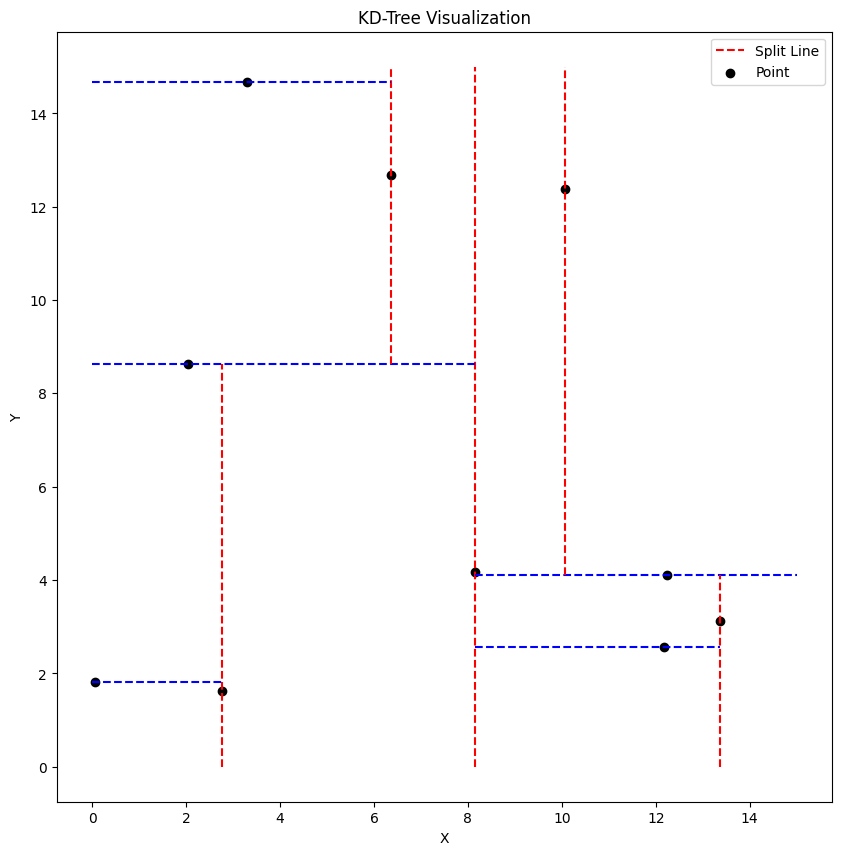

In [47]:
#Creating 10 points (x and y coordinates between 0 and 15)
myPoints = [
    (8.15, 4.17),
    (6.36, 12.67),
    (0.07, 1.82),
    (10.06, 12.38),
    (2.05, 8.62),
    (13.36, 3.13),
    (2.77, 1.62),
    (3.29, 14.67),
    (12.17, 2.57),
    (12.24, 4.11)
]

print("Points:")
for point in myPoints:
    print(point)


bounds = (0, 15, 0, 15)

tree = buildKDTree(myPoints, depth=0, bounds=bounds , visualize=False)
#Plotting the KD-Tree
plt.figure(figsize=(10,10))
plt.xlabel("X")
plt.ylabel("Y")
plt.title("KD-Tree Visualization")
plotKDTree(tree, bounds)
plt.legend(loc='upper right')
plt.show()

Points within range [(4, 10), (4, 10)] :
[7.90071864 6.71192883]
[7.26376008 4.08690554]
[5.53530123 4.93071762]
[7.19356205 6.42663864]
[7.74345256 5.0166804 ]
[4.25912064 8.74537683]
[4.22695775 8.23296276]
[4.21956837 7.21050502]
[4.1641448  9.02517248]
[8.05760663 7.085966  ]
[7.50878495 6.8747907 ]
[7.09591223 6.80380431]
[9.59387523 7.35313444]
[7.89400573 9.8433394 ]
[9.73782965 6.19179636]
[9.85733015 6.38540914]


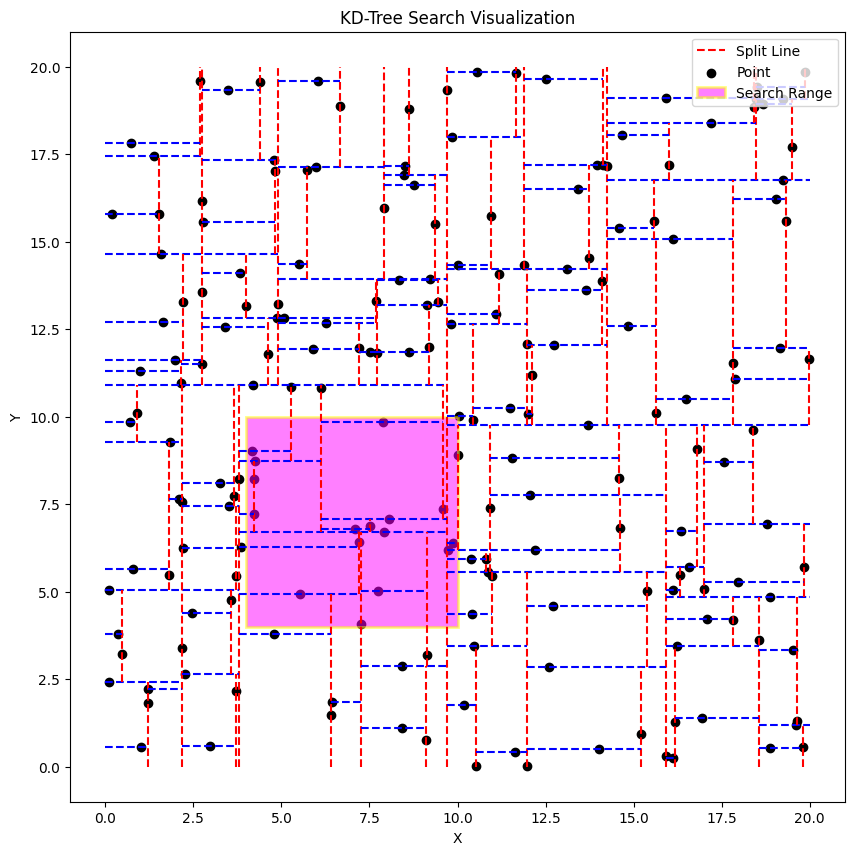

In [48]:
#Creating 200 random points (x and y coordinates between 0 and 20)
np.random.seed(100)
randomPoints1 = np.random.uniform(low=0,high=20,size=(200, 2))

#Setting the search range R and building the KD-Tree
R = [(4,10) , (4,10)]
bounds = (0, 20, 0, 20)
tree = buildKDTree(randomPoints1, depth=0, bounds=bounds , visualize=False)

#Searching the KD-Tree for points within range R
wantedPoints = searchKDTree(tree, R)
print("Points within range" ,R,":")
for point in wantedPoints:
    print(point) 

xMin, xMax = R[0]
yMin, yMax = R[1]

#Plotting the KD-Tree
figure , axis = plt.subplots(figsize=(10,10))
axis.set_xlabel("X")
axis.set_ylabel("Y")
axis.set_title("KD-Tree Search Visualization")
plotKDTree(tree,bounds)

#Drawing the search range rectangle and adding it to the plot
rectangle = plt.Rectangle((xMin, yMin), xMax - xMin, yMax - yMin, linewidth=2, edgecolor='yellow', alpha=0.5, facecolor='magenta', label='Search Range')
axis.add_patch(rectangle)


axis.legend(loc='upper right')
plt.show()


Όπως φαίνεται , στα παραπάνω διαγράμματα έχουμε δημιουργία και οπτικοποίηση ενός KD-Tree με 10 σημεία τα οποία εκτυπώνονται κιόλας για να είναι κατανοητές οι ακριβείς συντεταγμένες τους. Επίσης έχουμε ορθογώνια αναζήτηση ανάμεσα σε 200 τυχαία σημεία ζητώντας αυτά τα οποία βρίσκονται μέσα στην έκταση $R:[xmin,xmax] X [ymin.ymax]$. Το αποτέλεσμα οπτικοποιείται στο 2ο διάγραμμα όπου τα επιθυμητά σημεία βρίσκονται εντός του ορθογωνίου χρώματος magenta. Τα σημεία εκτυπώνονται κιόλας για να είναι κατανοητές οι ακριβείς συντεταγμένες τους.